<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day26_Carnegie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [1]:
url = ("https://raw.githubusercontent.com/ryanaxiom/Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
d["med_yn"] = (d["medical"] == 1).astype(int)
y = d["research"]
kf = KFold(n_splits=5, shuffle=True, random_state=309)
five = ["fallenr20", "totdeg", "facnum", "stem_rsd", "med_yn"]
print(carnegie.shape, d.shape)

(3939, 102) (302, 103)


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
four = ["fallenr20", "totdeg", "facnum", "stem_rsd"]
scaler4 = StandardScaler()
Z4 = scaler4.fit_transform(d[four])
km4 = KMeans(n_clusters=3, n_init=10, random_state=309)
km4.fit(Z4)
print(round(km4.inertia_, 1), np.bincount(km4.labels_))

393.7 [ 95  29 178]


In [3]:
labels = {"Johns Hopkins University": "JHU",
          "West Virginia University": "WVU",
          "Massachusetts Institute of Technology": "MIT",
          "Marshall University": "Marshall"}
raw = KMeans(n_clusters=3, n_init=10, random_state=309)
raw.fit(d[four])                                # no scaler
print(np.bincount(raw.labels_))
bands = d["fallenr20"].groupby(raw.labels_).agg(["min", "max"])
print(bands.values)
for full, short in labels.items():
    i = np.where(d["name"] == full)[0][0]
    print(short, raw.labels_[i], km4.labels_[i])

[151  45 106]
[[  255 16926]
 [36303 89816]
 [17311 36461]]
JHU 2 1
WVU 2 0
MIT 0 0
Marshall 0 2


1 1208.0
2 571.6
3 393.7
4 331.0
5 290.2
6 253.6
7 227.0
8 207.2


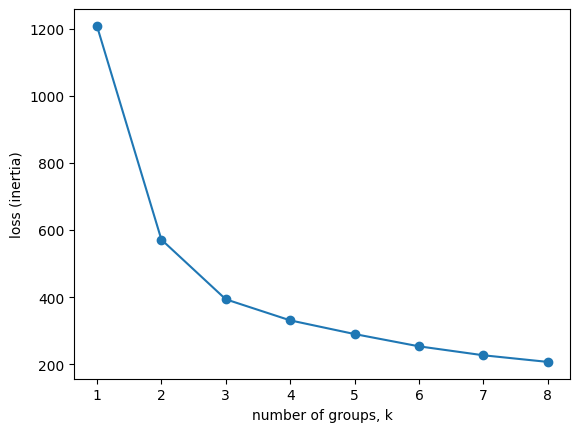

In [4]:
losses = []
for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=309)
    model.fit(Z4)
    losses.append(model.inertia_)
    print(k, round(model.inertia_, 1))
plt.plot(range(1, 9), losses, marker="o")
plt.xlabel("number of groups, k"); plt.ylabel("loss (inertia)"); plt.show()

           JHU   WVU   MIT  Marshall
JHU       0.00  2.92  3.41      4.22
WVU       2.92  0.00  3.14      1.64
MIT       3.41  3.14  0.00      3.71
Marshall  4.22  1.64  3.71      0.00
[[1.   3.   1.64 2.  ]
 [0.   2.   3.41 2.  ]
 [4.   5.   4.22 4.  ]]


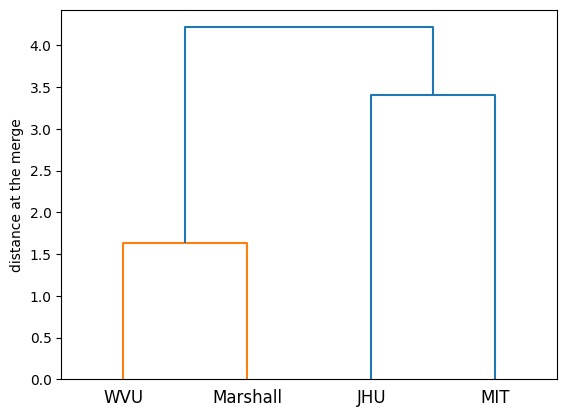

In [5]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
rows4 = [np.where(d["name"] == full)[0][0] for full in labels]
P4 = Z4[rows4]                                  # the four campuses
print(pd.DataFrame(squareform(pdist(P4)), index=labels.values(),
                   columns=labels.values()).round(2))
L4 = linkage(P4, method="complete")
print(L4.round(2))
dendrogram(L4, labels=list(labels.values()))
plt.ylabel("distance at the merge"); plt.show()

In [6]:
from sklearn.cluster import AgglomerativeClustering
lg = carnegie[carnegie["landgrnt"] == 1].copy()     # 1 means yes
dims = ["locale", "msi", "totdeg", "fallenr20", "selindex"]
hc = AgglomerativeClustering(n_clusters=3, linkage="complete")
hc.fit(lg[dims])                                # as inherited
print(len(lg), np.bincount(hc.labels_))
bands = lg["fallenr20"].groupby(hc.labels_).agg(["min", "max"])
print(bands.values)
wvu = np.where(lg["name"] == "West Virginia University")[0][0]
print(hc.labels_[wvu], lg["fallenr20"].values[wvu])

123 [103   3  17]
[[   79 34285]
 [61369 89816]
 [36042 53372]]
0 26269


In [7]:
kind_all = np.where(lg["tribal"] == 1, "tribal",
                    np.where(lg["hbcu"] == 1, "HBCU", "other"))
print(pd.crosstab(hc.labels_, kind_all))
print(list(lg["name"].values[hc.labels_ == 1]))

col_0  HBCU  other  tribal
row_0                     
0        23     45      35
1         0      3       0
2         0     17       0
['Ohio State University-Main Campus', 'Texas A & M University-College Station', 'The Pennsylvania State University']


In [8]:
def nearest(X, frame, n=5):
    X = np.asarray(X, dtype=float)
    me = np.where(frame["name"] == "West Virginia University")[0][0]
    dist = np.sqrt(((X - X[me])**2).sum(axis=1))
    order = np.argsort(dist)[1:n + 1]           # skip WVU itself
    return list(frame["name"].values[order])
inherited = nearest(lg[dims], lg)
by_size = nearest(lg[["fallenr20"]], lg)        # enrollment alone
print(inherited)
print(len(set(inherited) & set(by_size)), "of 5 on both lists")

['University of California-Riverside', 'Clemson University', 'University of Nebraska-Lincoln', 'University of Arkansas', 'University of California-Santa Barbara']
4 of 5 on both lists


In [9]:
show = ["West Virginia University"] + inherited
print(lg.set_index("name").loc[show, ["fallenr20"]])
print(by_size)

                                        fallenr20
name                                             
West Virginia University                    26269
University of California-Riverside          26434
Clemson University                          26406
University of Nebraska-Lincoln              25108
University of Arkansas                      27562
University of California-Santa Barbara      26179
['University of California-Santa Barbara', 'Clemson University', 'University of California-Riverside', 'University of Connecticut', 'University of Nebraska-Lincoln']


In [10]:
print(lg[dims].std().round(1).to_dict())        # the units
print(lg["locale"].value_counts().sort_index().to_dict())
print(lg["selindex"].value_counts().sort_index().to_dict())

{'locale': 13.1, 'msi': 0.5, 'totdeg': 5089.8, 'fallenr20': 18378.5, 'selindex': 0.9}
{-3: 1, 11: 18, 12: 14, 13: 21, 21: 8, 22: 3, 23: 5, 31: 3, 32: 8, 33: 9, 41: 7, 42: 9, 43: 17}
{0.0: 5, 1.0: 60, 2.0: 30, 3.0: 28}


In [11]:
odd = lg[(lg["locale"] < 0) | (lg["selindex"] == 0)]
print(odd[["name", "locale", "selindex"]].to_string(index=False))

                                                               name  locale  selindex
                                           Central State University      41       0.0
                                          College of Micronesia-FSM      -3       1.0
                                     Southern University Law Center      12       0.0
                                     University of Alaska Fairbanks      23       0.0
                             University of California-San Francisco      11       0.0
University of the District of Columbia-David A Clarke School of Law      11       0.0


In [12]:
ok = lg[(lg["locale"] > 0) & (lg["selindex"] > 0)].copy()
ok["urban"] = ok["locale"] // 10        # 1 city, 2, 3, 4 rural
fixed = ["urban", "msi", "totdeg", "fallenr20", "selindex"]
scaler = StandardScaler()
Z = scaler.fit_transform(ok[fixed])
hc2 = AgglomerativeClustering(n_clusters=3, linkage="complete")
hc2.fit(Z)
print(len(ok), np.bincount(hc2.labels_))
print(ok[fixed].groupby(hc2.labels_).mean().round(1))

117 [45 70  2]
   urban  msi   totdeg  fallenr20  selindex
0    1.2  0.1   9022.5    32966.3       2.6
1    3.0  0.8    931.6     4450.9       1.2
2    1.0  0.5  20505.5    80117.0       2.5


In [13]:
repaired = nearest(Z, ok)
print(repaired)
both = set(repaired) & set(inherited)
print(len(both), "of 5 were on the inherited list")

['Utah State University', 'University of Arkansas', 'University of Nebraska-Lincoln', 'University of Kentucky', 'University of Missouri-Columbia']
2 of 5 were on the inherited list


                                 fallenr20  totdeg  locale  msi  selindex
name                                                                     
West Virginia University             26269    6577      13    0       2.0
Utah State University                27691    6560      13    0       2.0
University of Arkansas               27562    6924      13    0       2.0
University of Nebraska-Lincoln       25108    6068      11    0       2.0
University of Kentucky               29986    7882      11    0       2.0
University of Missouri-Columbia      31089    7938      12    0       2.0
                                        fallenr20  totdeg  locale  msi  selindex
name                                                                            
University of California-Riverside          26434    6843      11    1       2.0
Clemson University                          26406    6915      21    0       3.0
University of California-Santa Barbara      26179    7931      22    1       3.0


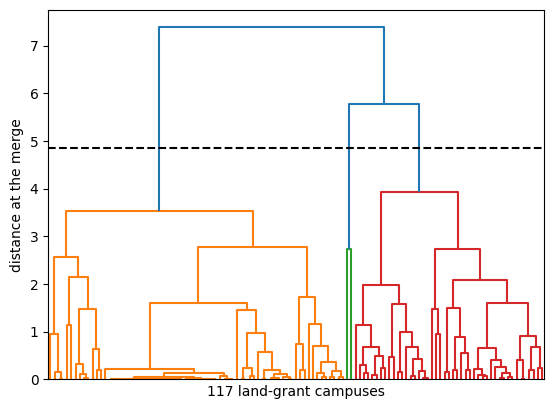

In [14]:
cols = ["fallenr20", "totdeg", "locale", "msi", "selindex"]
print(ok.set_index("name").loc[["West Virginia University"] + repaired, cols].to_string())
gone = [n for n in inherited if n not in repaired]
print(lg.set_index("name").loc[gone, cols].to_string())
tree = linkage(Z, method="complete")
cut = (tree[-3, 2] + tree[-2, 2]) / 2            # between the last two merges kept
dendrogram(tree, no_labels=True, color_threshold=cut)
plt.axhline(cut, color="black", linestyle="--")
plt.xlabel("117 land-grant campuses"); plt.ylabel("distance at the merge"); plt.show()

In [15]:
kind = np.where(ok["tribal"] == 1, "tribal",
                np.where(ok["hbcu"] == 1, "HBCU", "other"))
print(pd.crosstab(hc2.labels_, kind))
from sklearn.metrics import adjusted_rand_score
for link in ["average", "ward", "single"]:
    other = AgglomerativeClustering(n_clusters=3, linkage=link)
    other.fit(Z)
    ari = adjusted_rand_score(hc2.labels_, other.labels_)
    print(link, round(ari, 3))

col_0  HBCU  other  tribal
row_0                     
0         0     45       0
1        20     15      35
2         0      2       0
average 0.609
ward 0.525
single 0.068


In [16]:
from scipy.optimize import linear_sum_assignment
rng = np.random.default_rng(309)
arm = np.repeat(["A", "B", "C"], 21)             # 63 patients
flat = rng.normal(size=(63, 6))                  # six standardized changes, no arm effect
planted = flat.copy()
planted[arm == "C", :2] -= 1.5                   # arm C improves on two of them

def matched(found, truth):
    table = pd.crosstab(found, truth).values
    r, c = linear_sum_assignment(-table)         # the best relabeling
    return table[r, c].sum() / len(found)

shuffles = {}
for name, X in [("flat", flat), ("planted", planted)]:
    km_s = KMeans(n_clusters=3, n_init=10, random_state=309)
    km_s.fit(X)
    hit = matched(km_s.labels_, arm)
    null = np.array([matched(km_s.labels_, rng.permutation(arm))
                     for _ in range(2000)])
    shuffles[name] = (hit, null)
    print(name, round(float(hit), 3), round(float(null.mean()), 3),
          round(float(np.mean(null >= hit)), 4))

flat 0.429 0.416 0.388
planted 0.556 0.413 0.0015
